In [25]:
import torch
import numpy as np
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

In [26]:
torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cuda


In [27]:
class NeuralNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.flatten = nn.Flatten()
        self.layers = nn.Sequential(
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.flatten(x)
        x = self.layers(x)
        return x

In [28]:
model = NeuralNet().to(device)

loss_function = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [29]:
from torch.utils.data import DataLoader

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_dataset = torchvision.datasets.MNIST(
    root="/home/abubakr/Desktop/projects/handwritten_digit_mnist/data",
    train=True,
    download=True,
    transform=transform
)
test_dataset = torchvision.datasets.MNIST(
    root="/home/abubakr/Desktop/projects/handwritten_digit_mnist/data",
    train=False,
    download=True,
    transform=transform
)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=1000, shuffle=False)

In [30]:
def train_epoch(model, loss_function, optimizer, train_loader, device):
    model = model.to(device)

    model.train()

    total_loss = 0.0
    correct = 0
    total = 0
    

    for inputs, targets in train_loader:
        inputs, targets = inputs.to(device), targets.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)

        loss = loss_function(outputs, targets)
        loss.backward()
        optimizer.step()

        batch_size = targets.size(0)
        total_loss += loss.item() * batch_size
        
        
        _, predicted = torch.max(outputs, dim=1)
        correct += (predicted == targets).sum().item()
        total += batch_size
        
    avg_loss = total_loss / total
    accuracy = (correct / total) * 100

    print(f"AVG_LOSS: {avg_loss} | Accuracy: {accuracy:.2f}%")

    return avg_loss

In [31]:
def evaluate(model, loss_function, test_loader, device):
    model = model.to(device)
    model.eval()
    
    total_loss = 0.0
    correct = 0
    total = 0
    
    # Disable gradient calculation for faster evaluation and lower memory usage
    with torch.no_grad():
        for inputs, targets in test_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            
            outputs = model(inputs)
            loss = loss_function(outputs, targets)
            
            batch_size = targets.size(0)
            total_loss += loss.item() * batch_size
            
            _, predicted = torch.max(outputs, dim=1)
            correct += (predicted == targets).sum().item()
            total += batch_size
            
    avg_loss = total_loss / total
    accuracy = (correct / total) * 100
    print(f"test_avg_loss: {avg_loss} | test_accuracy: {accuracy}")
    return accuracy

In [32]:
num_epochs = 5

train_loss = []
test_acc = []

for epoch in range(num_epochs):
    print(f"{"="*50} Epoch {epoch+1} {"="*50}")
    print("Training:")
    loss = train_epoch(model, loss_function, optimizer, train_loader, device)
    train_loss.append(loss)

    print(f"Testing")
    accuracy = evaluate(model, loss_function, test_loader, device)
    test_acc.append(accuracy)


================================================== Epoch 1 ==================================================
Training:
AVG_LOSS: 0.2584777005871137 | Accuracy: 92.42%
Testing
test_avg_loss: 0.13356407471001147 | test_accuracy: 95.84
================================================== Epoch 2 ==================================================
Training:
AVG_LOSS: 0.11291541231175263 | Accuracy: 96.63%
Testing
test_avg_loss: 0.10106980111449956 | test_accuracy: 96.92
================================================== Epoch 3 ==================================================
Training:
AVG_LOSS: 0.07868609145482382 | Accuracy: 97.64%
Testing
test_avg_loss: 0.09767681136727333 | test_accuracy: 96.96000000000001
================================================== Epoch 4 ==================================================
Training:
AVG_LOSS: 0.06103717649529378 | Accuracy: 98.04%
Testing
test_avg_loss: 0.07326155956834554 | test_accuracy: 97.75
=================================================

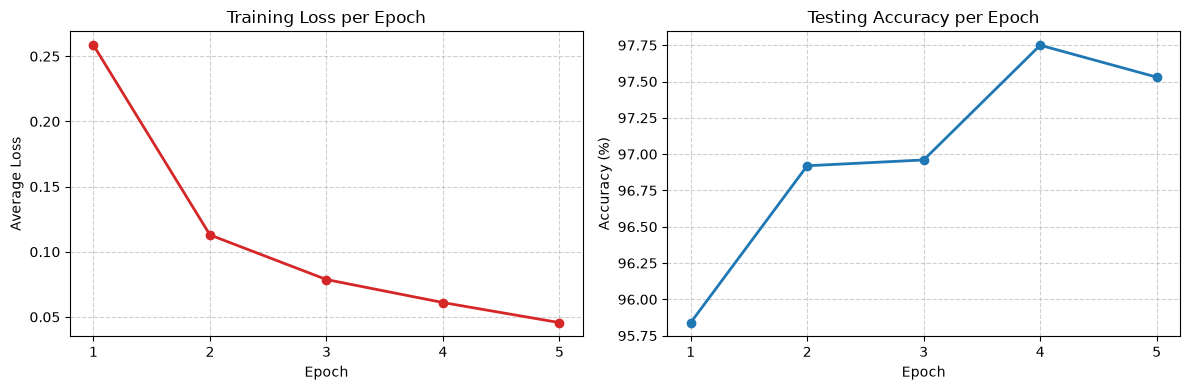

In [ ]:
epochs = range(1, num_epochs + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))


ax1.plot(epochs, train_loss, marker="o", color="tab:red", linewidth=2)
ax1.set_title("Training Loss per Epoch")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Average Loss")
ax1.set_xticks(epochs)
ax1.grid(True, linestyle="--", alpha=0.6)

ax2.plot(epochs, test_acc, marker="o", color="tab:blue", linewidth=2)
ax2.set_title("Testing Accuracy per Epoch")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy (%)")
ax2.set_xticks(epochs)
ax2.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()
